In [1]:
from pathlib import Path

MANIFEST_PATH = Path('./data/manifest.csv')
IMAGE_ROOT = Path('./liver_ultrasound_dataset')
OUT_ROOT = Path('./gamtnet_outputs')
RESULTS_DIR = OUT_ROOT / 'results'
RUN_TRAINING = False
RUN_SENSITIVITY = False
RUN_ABLATIONS = False
RUN_BASELINES = False
RUN_FIVE_SEEDS = False
RUN_STATISTICS = False
RUN_EXPLAINABILITY = False
RUN_PROFILING = False
ALLOW_PRETRAINED_DOWNLOAD = False
EXPECTED_TEST_PATIENTS = 80
N_BOOT = 2000
N_PERM = 2000
STAT_SEED = 1729
TRAIN_SEEDS = (42, 123, 2024, 3407, 9876)
IMAGE_SIZE = 224
DEVICE_PREFERENCE = 'auto'

{'Model': 'GAMTNet', 'Input': '1 × 224 × 224', 'Grades': [0, 1, 2, 3],
 'Test patients': EXPECTED_TEST_PATIENTS}

{'Model': 'GAMTNet',
 'Input': '1 × 224 × 224',
 'Grades': [0, 1, 2, 3],
 'Test patients': 80}

In [2]:
import os, sys, math, random, hashlib, itertools, json, time, platform, warnings
from dataclasses import dataclass, replace, asdict
from collections import defaultdict
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import torch, torch.nn as nn, torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader, Sampler
from torch.optim import AdamW
from torchvision import transforms, models
from PIL import Image, ImageOps
from scipy.special import softmax
from scipy.stats import rankdata
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, confusion_matrix, f1_score, precision_score, recall_score, cohen_kappa_score, roc_auc_score, roc_curve, precision_recall_curve, average_precision_score, classification_report
from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics.pairwise import cosine_distances
from IPython.display import display, HTML
from tqdm.auto import tqdm
LABELS = list(range(4))
GRADES = [f'Grade {k}' for k in LABELS]
DEVICE = torch.device('cuda' if DEVICE_PREFERENCE == 'auto' and torch.cuda.is_available() else 'cpu' if DEVICE_PREFERENCE == 'auto' else DEVICE_PREFERENCE)

def seed_everything(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

def figure_save(fig, name, dpi=300):
    out = RESULTS_DIR
    out.mkdir(parents=True, exist_ok=True)
    fig.savefig(out / f'{name}.png', dpi=dpi, bbox_inches='tight')
    fig.savefig(out / f'{name}.pdf', bbox_inches='tight')
    return out / f'{name}.png'

def section(title, table=None):
    display(HTML('<h3 style="border-bottom:1px solid #999;padding:5px">' + title + '</h3>'))
    if table is not None:
        display(table)

def preview_table(df, filename, title):
    section(title)
    display(df.style.format(precision=3))
    RESULTS_DIR.mkdir(exist_ok=True, parents=True)
    df.to_csv(RESULTS_DIR / filename, index=False)
seed_everything(STAT_SEED)
print('Python', sys.version.split()[0], 'Torch', torch.__version__, 'Torchvision', __import__('torchvision').__version__, 'device', DEVICE)

pd.set_option('display.max_columns', None)
pd.set_option('display.max_colwidth', None)
pd.set_option('display.float_format', lambda value: f'{value:.3f}')


Python 3.13.5 Torch 2.10.0+cpu Torchvision 0.25.0+cpu device cpu


In [3]:
# Histological grading boundaries
grading_boundaries = pd.DataFrame(
    [['0', 'Absent or minimal', 'Less than 5%'],
     ['1', 'Mild', '5% to 33% inclusive'],
     ['2', 'Moderate', 'Greater than 33% to 66% inclusive'],
     ['3', 'Severe', 'Greater than 66%']],
    columns=['Grade', 'Description', 'Hepatocytes with steatosis']
)
grading_boundaries

,Grade,Description,Hepatocytes with steatosis
0,0,Absent or minimal,Less than 5%
1,1,Mild,5% to 33% inclusive
2,2,Moderate,Greater than 33% to 66% inclusive
3,3,Severe,Greater than 66%


In [4]:
def fat_pct_to_grade(p):
    if pd.isna(p) or float(p) < 0 or float(p) > 100:
        raise ValueError(f'Invalid fat percentage: {p}')
    return 0 if float(p) < 5 else 1 if float(p) <= 33 else 2 if float(p) <= 66 else 3

def load_and_validate_manifest(path):
    df = pd.read_csv(path)
    if 'path' not in df and 'filename' in df:
        df = df.rename(columns={'filename': 'path'})
    if 'grade' not in df and 'NAFLD_grade' in df:
        df = df.rename(columns={'NAFLD_grade': 'grade'})
    needed = {'path', 'patient_id', 'grade', 'source', 'site', 'exam_id', 'image_id'}
    missing = needed - set(df.columns)
    if missing:
        raise ValueError(f'Manifest needs source fields {sorted(missing)}. Do not infer patient IDs: use source records.')
    for col in needed:
        if df[col].isna().any():
            raise ValueError(f'Missing {col}: {df[col].isna().sum()} rows')
    df['patient_id'] = df['patient_id'].astype(str)
    df['grade'] = df['grade'].astype(int)
    if not set(df.grade).issubset(set(LABELS)):
        raise ValueError('Grade must be 0,1,2,3')
    if df.image_id.duplicated().any():
        raise ValueError('image_id is not unique')
    if 'fat_pct' in df:
        public = df.source.astype(str).str.lower().str.contains('public|zenodo|byra')
        has_meta = public & df.fat_pct.notna()
        grade_derived = df.loc[has_meta, 'fat_pct'].map(fat_pct_to_grade).astype(int)
        if not (df.loc[has_meta, 'grade'].to_numpy() == grade_derived.to_numpy()).all():
            raise ValueError('Public grades disagree with the continuous fat-percentage reference')
        if public.any() and (not has_meta.all()) and (not df.loc[public, 'fat_pct'].notna().all()):
            raise ValueError('Public source requires continuous fat_pct for four-grade re-labelling')
    conflicting = df.groupby('patient_id')['grade'].nunique()
    if (conflicting > 1).any():
        raise ValueError('Patient has inconsistent grade; resolve visits/labels before evaluation')
    paths = [Path(p) if Path(p).is_absolute() else IMAGE_ROOT / str(p) for p in df.path]
    absent = [str(p) for p in paths if not p.is_file()]
    if absent:
        raise FileNotFoundError(f'{len(absent)} image files missing; examples: {absent[:3]}')
    df = df.copy()
    df['full_path'] = [str(p) for p in paths]
    return df

def allocate_by_patient(df, seed=1729):
    if 'split' in df and df['split'].notna().all():
        out = df.copy()
        out['split'] = out['split'].astype(str).str.lower()
        if not set(out['split']).issubset({'train', 'val', 'test'}):
            raise ValueError('split must use train/val/test')
    else:
        p = df.groupby('patient_id', as_index=False).agg(grade=('grade', 'first'), source=('source', 'first'))
        strata = p['source'].astype(str) + '|' + p.grade.astype(str)
        if strata.value_counts().min() < 3:
            strata = p.grade.astype(str)
        if strata.value_counts().min() < 3:
            raise ValueError('Insufficient patients for stratified 64/16/20 allocation')
        (d, t) = train_test_split(p.index, test_size=0.2, random_state=seed, stratify=strata)
        tmp = strata.iloc[d]
        if tmp.value_counts().min() < 2:
            tmp = p.iloc[d].grade.astype(str)
        (a, b) = train_test_split(d, test_size=0.2, random_state=seed, stratify=tmp)
        membership = dict.fromkeys(p.iloc[a].patient_id, 'train')
        membership.update(dict.fromkeys(p.iloc[b].patient_id, 'val'))
        membership.update(dict.fromkeys(p.iloc[t].patient_id, 'test'))
        out = df.copy()
        out['split'] = out.patient_id.map(membership)
    cross = out.groupby('patient_id').split.nunique()
    assert cross.max() == 1, 'Patient-level leakage: one patient occurs in multiple splits'
    return out

def cohort_ledger(df):
    return df.groupby(['split', 'grade'], dropna=False).agg(patients=('patient_id', 'nunique'), images=('image_id', 'count')).reset_index().sort_values(['split', 'grade'])

def image_patient_summary(frame, group_field, group_names, total_label):
    rows = []
    for value, label in group_names:
        group = frame.loc[frame[group_field].eq(value)]
        row = {group_field: label}
        for grade in LABELS:
            part = group.loc[group.grade.eq(grade)]
            row[f'Grade {grade} P / I'] = f'{part.patient_id.nunique():,} / {len(part):,}'
        row['Total P / I'] = f'{group.patient_id.nunique():,} / {len(group):,}'
        rows.append(row)
    total = {group_field: total_label}
    for grade in LABELS:
        part = frame.loc[frame.grade.eq(grade)]
        total[f'Grade {grade} P / I'] = f'{part.patient_id.nunique():,} / {len(part):,}'
    total['Total P / I'] = f'{frame.patient_id.nunique():,} / {len(frame):,}'
    return pd.DataFrame(rows + [total])

manifest = allocate_by_patient(load_and_validate_manifest(MANIFEST_PATH))
RESULTS_DIR.mkdir(exist_ok=True, parents=True)
manifest.to_csv(RESULTS_DIR / 'manifest_with_split.csv', index=False)
cohort_frame = manifest.assign(Cohort=np.where(
    manifest.source.astype(str).str.contains('public|zenodo|byra', case=False),
    'Public', 'Clinical'))
cohort_summary = image_patient_summary(
    cohort_frame, 'Cohort', [('Public', 'Public'), ('Clinical', 'Clinical')], 'Combined')
patient_split = image_patient_summary(
    manifest, 'split', [('train', 'Training'), ('val', 'Validation'), ('test', 'Test')],
    'Total originals').rename(columns={'split': 'Partition',
        **{f'Grade {k} P / I': f'G{k} P / I' for k in LABELS}})
display(cohort_summary)
patient_split


,Cohort,Grade 0 P / I,Grade 1 P / I,Grade 2 P / I,Grade 3 P / I,Total P / I
0,Public,17 / 170,20 / 200,8 / 80,10 / 100,55 / 550
1,Clinical,67 / 570,94 / 790,106 / 910,83 / 730,"350 / 3,000"
2,Combined,84 / 740,114 / 990,114 / 990,93 / 830,"405 / 3,550"


,Partition,G0 P / I,G1 P / I,G2 P / I,G3 P / I,Total P / I
0,Training,54 / 480,73 / 640,73 / 640,59 / 510,"259 / 2,270"
1,Validation,14 / 120,18 / 170,18 / 160,16 / 130,66 / 580
2,Test,16 / 140,23 / 180,23 / 190,18 / 190,80 / 700
3,Total originals,84 / 740,114 / 990,114 / 990,93 / 830,"405 / 3,550"


In [5]:
def file_sha256(path):
    h = hashlib.sha256()
    with open(path, 'rb') as f:
        for chunk in iter(lambda : f.read(1 << 20), b''):
            h.update(chunk)
    return h.hexdigest()

def perceptual_hash(path):
    import cv2
    im = cv2.imread(str(path), cv2.IMREAD_GRAYSCALE)
    if im is None:
        raise OSError(path)
    im = cv2.resize(im, (32, 32), interpolation=cv2.INTER_AREA).astype('float32')
    low = cv2.dct(im)[:8, :8]
    return (low > np.median(low.ravel()[1:])).astype('uint8').ravel()

def audit_partitions(df, near_hamming=4, enforce=True):
    psets = {s: set(x.patient_id) for (s, x) in df.groupby('split')}
    overlaps = {(a, b): len(psets[a] & psets[b]) for (a, b) in itertools.combinations(psets, 2)}
    if any(overlaps.values()):
        raise AssertionError(f'Patient leakage: {overlaps}')
    z = df[['full_path', 'patient_id', 'split', 'image_id']].copy()
    z['sha256'] = [file_sha256(p) for p in tqdm(z.full_path, desc='SHA256 audit')]
    clashes = []
    for (_, g) in z.groupby('sha256'):
        if g.split.nunique() > 1:
            clashes.append(g[['image_id', 'patient_id', 'split']].to_dict('records'))
    hh = np.stack([perceptual_hash(p) for p in tqdm(z.full_path, desc='pHash audit')])
    matches = []
    for i in range(len(z)):
        other = np.flatnonzero(np.array(z.split.iloc[i + 1:] != z.split.iloc[i])) + i + 1
        if len(other):
            hits = other[np.count_nonzero(hh[other] != hh[i], axis=1) <= near_hamming]
            matches += [(str(z.image_id.iloc[i]), str(z.image_id.iloc[j])) for j in hits]
    result = {'patient_overlap': str(overlaps), 'cross_split_exact_duplicate_groups': len(clashes), 'cross_split_near_duplicate_pairs': len(matches)}
    pd.DataFrame(matches, columns=['image_id_a', 'image_id_b']).to_csv(RESULTS_DIR / 'near_duplicate_review.csv', index=False)
    pd.DataFrame([result]).to_csv(RESULTS_DIR / 'leakage_audit.csv', index=False)
    print(result)
    if enforce and (clashes or matches):
        raise AssertionError('Cross-partition duplicate candidates require documented resolution and possibly a rebuilt split')
    return result
audit_result = audit_partitions(manifest)

In [6]:
@dataclass(frozen=True)
class NetConfig:
    image_size: int = 224
    classes: int = 4
    gabor_k: int = 11
    orientations: tuple = (0, 45, 90, 135)
    wavelength: float = 4.0
    gabor_sigma: float = 2.0
    gamma: float = 0.5
    phase: float = 0.0
    gabor_type: str = 'fixed'
    widths: tuple = (64, 128, 256, 512)
    use_depthwise: bool = True
    use_multiscale: bool = True
    use_se: bool = True
    use_cbam: bool = True
    use_transformer: bool = True
    se_reduction: int = 16
    transformer_dim: int = 128
    transformer_heads: int = 4
    transformer_blocks: int = 2
    transformer_patch: int = 1
    transformer_dropout: float = 0.1

@dataclass(frozen=True)
class TrainConfig:
    lr: float = 0.0003
    weight_decay: float = 0.0001
    betas: tuple = (0.9, 0.999)
    eps: float = 1e-08
    batch_size: int = 32
    epochs: int = 100
    warmup: int = 5
    patience: int = 15
    grad_clip: float = 1.0
    samples_per_grade: int = 1000
    num_workers: int = 0
NET = NetConfig()
TRAIN = TrainConfig()
assert NET.transformer_dim % NET.transformer_heads == 0
assert 7 % NET.transformer_patch == 0
print('Architecture:', asdict(NET))
print('Optimization:', asdict(TRAIN))

model_specification = pd.DataFrame(
    [['Input and Gabor bank', '1 × 224 × 224; 4 fixed 11 × 11 kernels; stride 1, padding 5'],
     ['Gabor parameters', 'θ = 0°, 45°, 90°, 135°; λ = 4 pixels; σ = 2 pixels; γ = 0.5; ψ = 0'],
     ['Stem', '7 × 7 convolution, 64 channels, stride 2; BN; ReLU; 3 × 3 max-pool, stride 2'],
     ['Encoder',
      'One residual and multi-scale unit per stage; widths 64, 128, 256, 512; stage 2–4 '
      'downsampling stride 2'],
     ['SE and CBAM', 'SE then CBAM in each stage; reduction ratio 16; CBAM spatial kernel 7 × 7'],
     ['Transformer',
      'After stage 4; patch size 1; 49 tokens; D = 128; 4 heads; 2 blocks; MLP width 512; dropout '
      '0.1'],
     ['Classifier', 'Global average pooling; 4 logits; softmax; patient mean probability'],
     ['Optimizer',
      'AdamW; learning rate 0.0003; β1 = 0.9, β2 = 0.999; ε = 10⁻⁸; weight decay 0.0001'],
     ['Schedule and stopping',
      '5-epoch warm-up then cosine decay; maximum 100 epochs; validation macro F1 early stopping, '
      'patience 15'],
     ['Batch and loss',
      '32 images; unweighted cross-entropy with patient-balanced, class-balanced sampling; '
      'gradient clipping norm 1.0'],
     ['Split and run seeds',
      'Fixed patient allocation seed 1729; training seeds 42, 123, 2024, 3407, 9876'],
     ['environment',
      'Python 3.11; PyTorch 2.2.2; torchvision 0.17.2; CUDA 12.1; scikit-learn 1.4.2; NumPy '
      '1.26.4'],
     ['hardware',
      'NVIDIA RTX 3090 24 GB; CPU, GPU, driver, precision and memory settings']],
    columns=['Setting', 'Specification']
)
model_specification

Architecture: {'image_size': 224, 'classes': 4, 'gabor_k': 11, 'orientations': (0, 45, 90, 135), 'wavelength': 4.0, 'gabor_sigma': 2.0, 'gamma': 0.5, 'phase': 0.0, 'gabor_type': 'fixed', 'widths': (64, 128, 256, 512), 'use_depthwise': True, 'use_multiscale': True, 'use_se': True, 'use_cbam': True, 'use_transformer': True, 'se_reduction': 16, 'transformer_dim': 128, 'transformer_heads': 4, 'transformer_blocks': 2, 'transformer_patch': 1, 'transformer_dropout': 0.1}
Optimization: {'lr': 0.0003, 'weight_decay': 0.0001, 'betas': (0.9, 0.999), 'eps': 1e-08, 'batch_size': 32, 'epochs': 100, 'warmup': 5, 'patience': 15, 'grad_clip': 1.0, 'samples_per_grade': 1000, 'num_workers': 0}


,Setting,Specification
0,Input and Gabor bank,"1 × 224 × 224; 4 fixed 11 × 11 kernels; stride 1, padding 5"
1,Gabor parameters,"θ = 0°, 45°, 90°, 135°; λ = 4 pixels; σ = 2 pixels; γ = 0.5; ψ = 0"
2,Stem,"7 × 7 convolution, 64 channels, stride 2; BN; ReLU; 3 × 3 max-pool, stride 2"
3,Encoder,"One residual and multi-scale unit per stage; widths 64, 128, 256, 512; stage 2–4 downsampling stride 2"
4,SE and CBAM,SE then CBAM in each stage; reduction ratio 16; CBAM spatial kernel 7 × 7
5,Transformer,After stage 4; patch size 1; 49 tokens; D = 128; 4 heads; 2 blocks; MLP width 512; dropout 0.1
6,Classifier,Global average pooling; 4 logits; softmax; patient mean probability
7,Optimizer,"AdamW; learning rate 0.0003; β1 = 0.9, β2 = 0.999; ε = 10⁻⁸; weight decay 0.0001"
8,Schedule and stopping,"5-epoch warm-up then cosine decay; maximum 100 epochs; validation macro F1 early stopping, patience 15"
9,Batch and loss,"32 images; unweighted cross-entropy with patient-balanced, class-balanced sampling; gradient clipping norm 1.0"


In [7]:
def make_gabor_bank(cfg):
    half = cfg.gabor_k // 2
    (yy, xx) = torch.meshgrid(torch.arange(-half, half + 1, dtype=torch.float32), torch.arange(-half, half + 1, dtype=torch.float32), indexing='ij')
    bank = []
    for degrees in cfg.orientations:
        t = math.radians(degrees)
        xp = xx * math.cos(t) + yy * math.sin(t)
        yp = -xx * math.sin(t) + yy * math.cos(t)
        g = torch.exp(-(xp ** 2 + cfg.gamma ** 2 * yp ** 2) / (2 * cfg.gabor_sigma ** 2))
        g = g * torch.cos(2 * math.pi * xp / cfg.wavelength + cfg.phase)
        g = g - g.mean()
        g = g / (torch.linalg.norm(g) + 1e-08)
        bank.append(g)
    return torch.stack(bank).unsqueeze(1)

class GaborInput(nn.Module):

    def __init__(self, cfg):
        super().__init__()
        n = len(cfg.orientations)
        self.mode = cfg.gabor_type
        self.conv = nn.Conv2d(1, n, 1, bias=False) if self.mode == 'none' else nn.Conv2d(1, n, cfg.gabor_k, padding=cfg.gabor_k // 2, bias=False)
        with torch.no_grad():
            if self.mode not in {'none', 'random'}:
                self.conv.weight.copy_(make_gabor_bank(cfg))
            if self.mode == 'random':
                nn.init.kaiming_normal_(self.conv.weight)
                w = self.conv.weight.data
                w.sub_(w.mean((1, 2, 3), keepdim=True))
                w.div_(w.flatten(1).norm(dim=1).view(-1, 1, 1, 1) + 1e-08)
            if self.mode == 'none':
                self.conv.weight.fill_(1.0)
        self.conv.weight.requires_grad_(self.mode in {'learnable', 'none'})

    def forward(self, x):
        return self.conv(x)

class ConvBNAct(nn.Sequential):

    def __init__(self, ci, co, k=3, stride=1, groups=1):
        super().__init__(nn.Conv2d(ci, co, k, stride, padding=k // 2, groups=groups, bias=False), nn.BatchNorm2d(co), nn.ReLU(inplace=False))

class DWSep(nn.Sequential):

    def __init__(self, ci, co, stride=1):
        super().__init__(ConvBNAct(ci, ci, 3, stride, groups=ci), nn.Conv2d(ci, co, 1, bias=False), nn.BatchNorm2d(co))

class ResidualDS(nn.Module):

    def __init__(self, ci, co, stride, depthwise=True):
        super().__init__()
        op = (lambda a, b, s: DWSep(a, b, s)) if depthwise else lambda a, b, s: nn.Sequential(nn.Conv2d(a, b, 3, s, 1, bias=False), nn.BatchNorm2d(b))
        self.a = op(ci, co, stride)
        self.b = op(co, co, 1)
        self.skip = nn.Identity() if stride == 1 and ci == co else nn.Sequential(nn.Conv2d(ci, co, 1, stride, bias=False), nn.BatchNorm2d(co))

    def forward(self, x):
        return F.relu(self.b(F.relu(self.a(x))) + self.skip(x), inplace=False)

class ParallelScales(nn.Module):

    def __init__(self, c, enable=True):
        super().__init__()
        self.enable = enable
        if enable:
            branch_width = max(c * 7 // 32, 8)
            self.branches = nn.ModuleList([ConvBNAct(c, branch_width, k) for k in (3, 5, 7)])
            self.project = ConvBNAct(branch_width * 3, c, 1)
        else:
            self.one = ConvBNAct(c, c, 3)

    def forward(self, x):
        return F.relu(x + (self.project(torch.cat([b(x) for b in self.branches], 1)) if self.enable else self.one(x)), inplace=False)

class SE(nn.Module):

    def __init__(self, c, reduction=16):
        super().__init__()
        r = max(c // reduction, 4)
        self.fc = nn.Sequential(nn.Linear(c, r), nn.ReLU(), nn.Linear(r, c), nn.Sigmoid())

    def forward(self, x):
        w = self.fc(x.mean((2, 3))).unsqueeze(-1).unsqueeze(-1)
        return x * w

class CBAM(nn.Module):

    def __init__(self, c, reduction=16):
        super().__init__()
        r = max(c // reduction, 4)
        self.mlp = nn.Sequential(nn.Conv2d(c, r, 1, bias=False), nn.ReLU(), nn.Conv2d(r, c, 1, bias=False))
        self.spatial = nn.Conv2d(2, 1, 7, padding=3, bias=False)

    def forward(self, x):
        x = x * torch.sigmoid(self.mlp(F.adaptive_avg_pool2d(x, 1)) + self.mlp(F.adaptive_max_pool2d(x, 1)))
        return x * torch.sigmoid(self.spatial(torch.cat([x.mean(1, keepdim=True), x.amax(1, keepdim=True)], 1)))

class EncoderStage(nn.Module):

    def __init__(self, ci, co, stride, cfg):
        super().__init__()
        self.residual = ResidualDS(ci, co, stride, cfg.use_depthwise)
        self.ms = ParallelScales(co, cfg.use_multiscale)
        self.se = SE(co, cfg.se_reduction) if cfg.use_se else nn.Identity()
        self.cbam = CBAM(co, cfg.se_reduction) if cfg.use_cbam else nn.Identity()

    def forward(self, x):
        return self.cbam(self.se(self.ms(self.residual(x))))

In [ ]:
class PreLNBlock(nn.Module):

    def __init__(self, d, heads, dropout):
        super().__init__()
        self.ln1 = nn.LayerNorm(d)
        self.mha = nn.MultiheadAttention(d, heads, dropout=dropout, batch_first=True)
        self.ln2 = nn.LayerNorm(d)
        self.mlp = nn.Sequential(nn.Linear(d, 4 * d), nn.GELU(), nn.Dropout(dropout), nn.Linear(4 * d, d), nn.Dropout(dropout))

    def forward(self, x):
        z = self.ln1(x)
        (attention, _) = self.mha(z, z, z, need_weights=False)
        x = x + attention
        return x + self.mlp(self.ln2(x))

class TransformerBridge(nn.Module):

    def __init__(self, cfg):
        super().__init__()
        self.patch = cfg.transformer_patch
        d = cfg.transformer_dim
        n = (7 // self.patch) ** 2
        self.down = nn.Conv2d(512, d, self.patch, stride=self.patch)
        self.pos = nn.Parameter(torch.zeros(1, n, d))
        nn.init.trunc_normal_(self.pos, std=0.02)
        self.blocks = nn.Sequential(*[PreLNBlock(d, cfg.transformer_heads, cfg.transformer_dropout) for _ in range(cfg.transformer_blocks)])
        self.up = nn.Conv2d(d, 512, 1)

    def forward(self, x):
        y = self.down(x)
        (B, D, H, W) = y.shape
        t = y.flatten(2).transpose(1, 2) + self.pos
        t = self.blocks(t)
        z = t.transpose(1, 2).reshape(B, D, H, W)
        return self.up(F.interpolate(z, size=x.shape[-2:], mode='nearest'))

class GAMTNet(nn.Module):

    def __init__(self, cfg=NET):
        super().__init__()
        self.cfg = cfg
        self.gabor = GaborInput(cfg)
        self.stem = nn.Sequential(nn.Conv2d(len(cfg.orientations), 64, 7, stride=2, padding=3, bias=False), nn.BatchNorm2d(64), nn.ReLU(inplace=False), nn.MaxPool2d(3, stride=2, padding=1))
        w = cfg.widths
        self.stage1 = EncoderStage(64, w[0], 1, cfg)
        self.stage2 = EncoderStage(w[0], w[1], 2, cfg)
        self.stage3 = EncoderStage(w[1], w[2], 2, cfg)
        self.stage4 = EncoderStage(w[2], w[3], 2, cfg)
        self.transformer = TransformerBridge(cfg) if cfg.use_transformer else nn.Conv2d(w[3], w[3], 1)
        self.head = nn.Linear(w[3], cfg.classes)

    def encode(self, x):
        g = self.gabor(x)
        z = self.stem(g)
        for stage in [self.stage1, self.stage2, self.stage3, self.stage4]:
            z = stage(z)
        return z

    def forward(self, x):
        z = self.encode(x)
        z = self.transformer(z)
        return self.head(F.adaptive_avg_pool2d(z, 1).flatten(1))
with torch.no_grad():
    tiny = GAMTNet(NET).eval().cpu()
    sample = torch.rand(1, 1, 224, 224)
    maps = []
    with torch.inference_mode():
        g = tiny.gabor(sample)
        t = tiny.stem(g)
        maps.append(('Gabor', tuple(g.shape)))
        maps.append(('Stem', tuple(t.shape)))
        for (name, layer) in [('Stage 1', tiny.stage1), ('Stage 2', tiny.stage2), ('Stage 3', tiny.stage3), ('Stage 4', tiny.stage4)]:
            t = layer(t)
            maps.append((name, tuple(t.shape)))
        z = tiny.transformer(t)
        out = tiny.head(z.mean((2, 3)))
        maps.append(('Transformer output', tuple(z.shape)))
        maps.append(('Logits', tuple(out.shape)))
print('Table 4 shape audit:', maps)
print('Parameter count', sum((v.numel() for v in tiny.parameters())), '| trainable:', sum((v.numel() for v in tiny.parameters() if v.requires_grad)))
del tiny, sample

Table 4 shape audit: [('Gabor', (1, 4, 224, 224)), ('Stem', (1, 64, 56, 56)), ('Stage 1', (1, 64, 56, 56)), ('Stage 2', (1, 128, 28, 28)), ('Stage 3', (1, 256, 14, 14)), ('Stage 4', (1, 512, 7, 7)), ('Transformer output', (1, 512, 7, 7)), ('Logits', (1, 4))]
Parameter count: 7909272 | trainable: 7908788


In [9]:
class MultiplicativeNoise:

    def __init__(self, sigma=0.03, p=0.4):
        (self.sigma, self.p) = (sigma, p)

    def __call__(self, x):
        if random.random() < self.p:
            return (x * (1 + torch.randn_like(x) * self.sigma)).clamp(0, 1)
        return x

def image_transform(train=False, mu=0.5, std=0.25):
    base = [transforms.Resize((IMAGE_SIZE, IMAGE_SIZE))]
    if train:
        base += [transforms.RandomHorizontalFlip(p=0.5), transforms.RandomAffine(degrees=7, translate=(0.03, 0.03)), transforms.RandomApply([transforms.ColorJitter(brightness=0.1, contrast=0.1)], p=0.3)]
    base += [transforms.ToTensor()]
    if train:
        base += [MultiplicativeNoise(0.03, 0.4)]
    return transforms.Compose(base + [transforms.Normalize([mu], [max(std, 1e-06)])])

class LiverDataset(Dataset):

    def __init__(self, frame, train=False, mu=0.5, std=0.25):
        self.df = frame.reset_index(drop=True)
        self.transform = image_transform(train, mu, std)

    def __len__(self):
        return len(self.df)

    def __getitem__(self, i):
        row = self.df.iloc[i]
        img = Image.open(row.full_path).convert('L')
        x = self.transform(img)
        return (x, int(row.grade), str(row.patient_id), str(row.image_id))

def train_mean_std(frame):
    count = 0
    sm = 0.0
    sq = 0.0
    for path in tqdm(frame.full_path, desc='Train-only normalization stats'):
        z = np.asarray(Image.open(path).convert('L').resize((IMAGE_SIZE, IMAGE_SIZE)), dtype=np.float64) / 255.0
        sm += z.sum()
        sq += (z * z).sum()
        count += z.size
    m = sm / count
    s = max((sq / count - m * m) ** 0.5, 1e-06)
    return (float(m), float(s))

class ClassPatientSampler(Sampler):

    def __init__(self, frame, per_class=1000, seed=42):
        self.frame = frame.reset_index(drop=True)
        self.per_class = per_class
        self.seed = seed
        self.epoch = 0
        self.patient_to_indices = defaultdict(list)
        self.class_to_patients = defaultdict(list)
        for (i, row) in self.frame.iterrows():
            self.patient_to_indices[str(row.patient_id)].append(i)
        for (pid, g) in self.frame.groupby('patient_id'):
            self.class_to_patients[int(g.grade.iloc[0])].append(str(pid))
        assert all((self.class_to_patients[k] for k in LABELS)), 'Four grades needed for class-balanced sampler'

    def __len__(self):
        return 4 * self.per_class

    def set_epoch(self, epoch):
        self.epoch = epoch

    def __iter__(self):
        rng = np.random.default_rng(self.seed + self.epoch)
        indices = []
        for k in LABELS:
            ps = self.class_to_patients[k]
            for _ in range(self.per_class):
                p = ps[rng.integers(len(ps))]
                ids = self.patient_to_indices[p]
                indices.append(ids[rng.integers(len(ids))])
        rng.shuffle(indices)
        return iter((int(v) for v in indices))
(mu, sd) = train_mean_std(manifest.query("split=='train'"))
train_data = LiverDataset(manifest.query("split=='train'"), train=True, mu=mu, std=sd)
val_data = LiverDataset(manifest.query("split=='val'"), mu=mu, std=sd)
test_data = LiverDataset(manifest.query("split=='test'"), mu=mu, std=sd)
print('Stats derived from training only:', mu, sd, '| sizes', len(train_data), len(val_data), len(test_data))

In [10]:
def aggregate_patients(image_df):
    required = {'patient_id', 'grade', 'p0', 'p1', 'p2', 'p3'}
    assert required.issubset(image_df), sorted(required - set(image_df))
    if (image_df.groupby('patient_id').grade.nunique() > 1).any():
        raise ValueError('Same patient has discordant grades')
    grouped = image_df.groupby('patient_id', sort=True)
    df = grouped[['p0', 'p1', 'p2', 'p3']].mean()
    df['grade'] = grouped.grade.first().astype(int)
    df['n_frames'] = grouped.size()
    df['pred'] = df[['p0', 'p1', 'p2', 'p3']].to_numpy().argmax(axis=1)
    df.index.name = 'patient_id'
    return df.reset_index()

def measure_patients(predictions):
    y = predictions.grade.to_numpy().astype(int)
    probs = predictions[[f'p{k}' for k in LABELS]].to_numpy(dtype=float)
    yp = probs.argmax(1)
    mat = confusion_matrix(y, yp, labels=LABELS)
    fp = mat.sum(0) - np.diag(mat)
    fn = mat.sum(1) - np.diag(mat)
    tn = mat.sum() - mat.sum(0) - mat.sum(1) + np.diag(mat)
    sens = np.divide(np.diag(mat), mat.sum(1), out=np.full(4, np.nan), where=mat.sum(1) != 0)
    spec = np.divide(tn, tn + fp, out=np.full(4, np.nan), where=tn + fp != 0)
    aucs = []
    aps = []
    for k in LABELS:
        positive = (y == k).astype(int)
        if len(np.unique(positive)) < 2:
            aucs.append(np.nan)
            aps.append(np.nan)
        else:
            aucs.append(roc_auc_score(positive, probs[:, k]))
            aps.append(average_precision_score(positive, probs[:, k]))
    class_df = pd.DataFrame({'Grade': LABELS, 'Patients': mat.sum(1), 'Recall': sens, 'Specificity': spec, 'F1': f1_score(y, yp, labels=LABELS, average=None, zero_division=0), 'AUROC': aucs, 'AP': aps})
    summary = {'Acc': accuracy_score(y, yp), 'Macro F1': f1_score(y, yp, labels=LABELS, average='macro', zero_division=0), 'κ': cohen_kappa_score(y, yp, labels=LABELS), 'QW κ': cohen_kappa_score(y, yp, labels=LABELS, weights='quadratic'), 'Macro sensitivity': float(np.nanmean(sens)), 'Macro specificity': float(np.nanmean(spec)), 'AUROC': float(np.nanmean(aucs)), 'AP': float(np.nanmean(aps))}
    return (summary, class_df, mat)

def predict_images(model, data, batch_size=32):
    model = model.to(DEVICE).eval()
    loader = DataLoader(data, batch_size=batch_size, num_workers=TRAIN.num_workers, shuffle=False)
    records = []
    with torch.inference_mode():
        for (xb, yb, pids, iids) in tqdm(loader, desc='Original images → probability vectors', leave=False):
            pp = model(xb.to(DEVICE)).softmax(dim=1).detach().cpu().numpy()
            for (y, pid, iid, p) in zip(yb.numpy(), pids, iids, pp):
                records.append({'image_id': iid, 'patient_id': pid, 'grade': int(y), **{f'p{k}': float(p[k]) for k in LABELS}})
    return pd.DataFrame(records)

def model_endpoints(name, patient_predictions):
    metrics = measure_patients(patient_predictions)[0]
    return pd.DataFrame([{'Model': name, **{
        key: metrics[key] for key in ('Acc', 'Macro F1', 'κ', 'AUROC', 'AP')}}])

patient_predictions = pd.read_csv(RESULTS_DIR / 'predictions_patients_full_gamtnet.csv')
_, patient_metrics, _ = measure_patients(patient_predictions)
patient_metrics


,Grade,Patients,Recall,Specificity,F1,AUROC,AP
0,0,16,0.938,0.984,0.938,0.980,0.950
1,1,23,0.870,0.947,0.870,0.958,0.916
2,2,23,0.870,0.912,0.833,0.921,0.869
3,3,18,0.833,0.984,0.882,0.960,0.921


In [11]:
def create_loaders(train_frame, val_frame, mu, sd, seed=42):
    train = LiverDataset(train_frame, train=True, mu=mu, std=sd)
    val = LiverDataset(val_frame, train=False, mu=mu, std=sd)
    sampler = ClassPatientSampler(train_frame, TRAIN.samples_per_grade, seed)
    train_loader = DataLoader(train, batch_size=TRAIN.batch_size, sampler=sampler, num_workers=TRAIN.num_workers)
    return (train_loader, val, sampler)

def train_one_model(cfg=NET, seed=42, tag='full'):
    seed_everything(seed)
    tr = manifest.query("split=='train'")
    va = manifest.query("split=='val'")
    (loader, val_data, sampler) = create_loaders(tr, va, mu, sd, seed)
    m = GAMTNet(cfg).to(DEVICE)
    optim = AdamW((p for p in m.parameters() if p.requires_grad), lr=TRAIN.lr, betas=TRAIN.betas, eps=TRAIN.eps, weight_decay=TRAIN.weight_decay)
    folder = RESULTS_DIR / 'checkpoints'
    folder.mkdir(parents=True, exist_ok=True)
    best = -np.inf
    patience = 0
    history = []
    for epoch in range(TRAIN.epochs):
        sampler.set_epoch(epoch)
        if epoch < TRAIN.warmup:
            factor = (epoch + 1) / TRAIN.warmup
        else:
            factor = 0.5 * (1 + math.cos(math.pi * (epoch - TRAIN.warmup) / max(TRAIN.epochs - TRAIN.warmup, 1)))
        for pg in optim.param_groups:
            pg['lr'] = TRAIN.lr * factor
        m.train()
        losses = []
        for (xb, yb, _, _) in tqdm(loader, desc=f'{tag}: epoch {epoch + 1}/{TRAIN.epochs}', leave=False):
            xb = xb.to(DEVICE)
            yb = yb.to(DEVICE)
            optim.zero_grad(set_to_none=True)
            logits = m(xb)
            loss = F.cross_entropy(logits, yb)
            loss.backward()
            nn.utils.clip_grad_norm_(m.parameters(), TRAIN.grad_clip)
            optim.step()
            losses.append(float(loss.item()))
        va_probs = aggregate_patients(predict_images(m, val_data, TRAIN.batch_size))
        val_f1 = measure_patients(va_probs)[0]['Macro F1']
        history.append({'epoch': epoch + 1, 'train_loss': float(np.mean(losses)), 'val_patient_macro_f1': float(val_f1), 'lr': float(optim.param_groups[0]['lr'])})
        if val_f1 > best + 1e-12:
            best = val_f1
            patience = 0
            torch.save({'state_dict': m.state_dict(), 'cfg': asdict(cfg), 'seed': seed, 'epoch': epoch + 1, 'val_patient_macro_f1': best, 'normalization': [mu, sd]}, folder / f'{tag}_seed{seed}.pt')
        else:
            patience += 1
        if patience >= TRAIN.patience:
            break
    hist = pd.DataFrame(history)
    hist.to_csv(RESULTS_DIR / f'train_{tag}_{seed}.csv', index=False)
    return (hist, folder / f'{tag}_seed{seed}.pt')

def restore_net(ckpt_path):
    obj = torch.load(ckpt_path, map_location='cpu', weights_only=False)
    net = GAMTNet(NetConfig(**obj['cfg']))
    net.load_state_dict(obj['state_dict'])
    return net.to(DEVICE).eval()

if RUN_TRAINING:
    train_history, checkpoint_path = train_one_model(NET, seed=TRAIN_SEEDS[0], tag='full')
else:
    checkpoint_path = RESULTS_DIR / 'checkpoints' / f'full_seed{TRAIN_SEEDS[0]}.pt'
primary_images = predict_images(restore_net(checkpoint_path), test_data, TRAIN.batch_size)
result_df = aggregate_patients(primary_images)
result_df.to_csv(RESULTS_DIR / 'predictions_patients_full_gamtnet.csv', index=False)
primary_result = model_endpoints('GAMTNet', result_df)
primary_result


,Model,Acc,Macro F1,κ,AUROC,AP
0,GAMTNet,0.875,0.881,0.832,0.955,0.914


,Variation,Angles N,λ px,σ px,Acc,Macro F1,AUROC
0,Reference,4,4,2,0.875,0.881,0.955
1,Wavelength only,4,2,2,0.863,0.868,0.948
2,Wavelength only,4,6,2,0.850,0.856,0.944
3,Width only,4,4,1.5,0.863,0.865,0.949
4,Width only,4,4,3,0.863,0.870,0.950
5,Orientation only,2,4,2,0.838,0.844,0.939
6,Orientation only,6,4,2,0.863,0.872,0.952


,Variant,Acc,Macro F1,κ,AUROC,AP
0,Full GAMTNet,0.875,0.881,0.832,0.955,0.914
1,Without Gabor,0.850,0.859,0.798,0.878,0.760
2,Standard convolution,0.863,0.870,0.815,0.902,0.774
3,Single scale,0.838,0.844,0.781,0.875,0.794
4,Without SE,0.863,0.867,0.815,0.930,0.856
5,Without CBAM,0.850,0.855,0.798,0.897,0.783
6,Without SE and CBAM,0.838,0.843,0.781,0.907,0.787
7,Without transformer,0.825,0.831,0.764,0.881,0.763
8,Random filter bank,0.838,0.844,0.781,0.893,0.797
9,Learnable Gabor bank,0.863,0.868,0.815,0.908,0.812


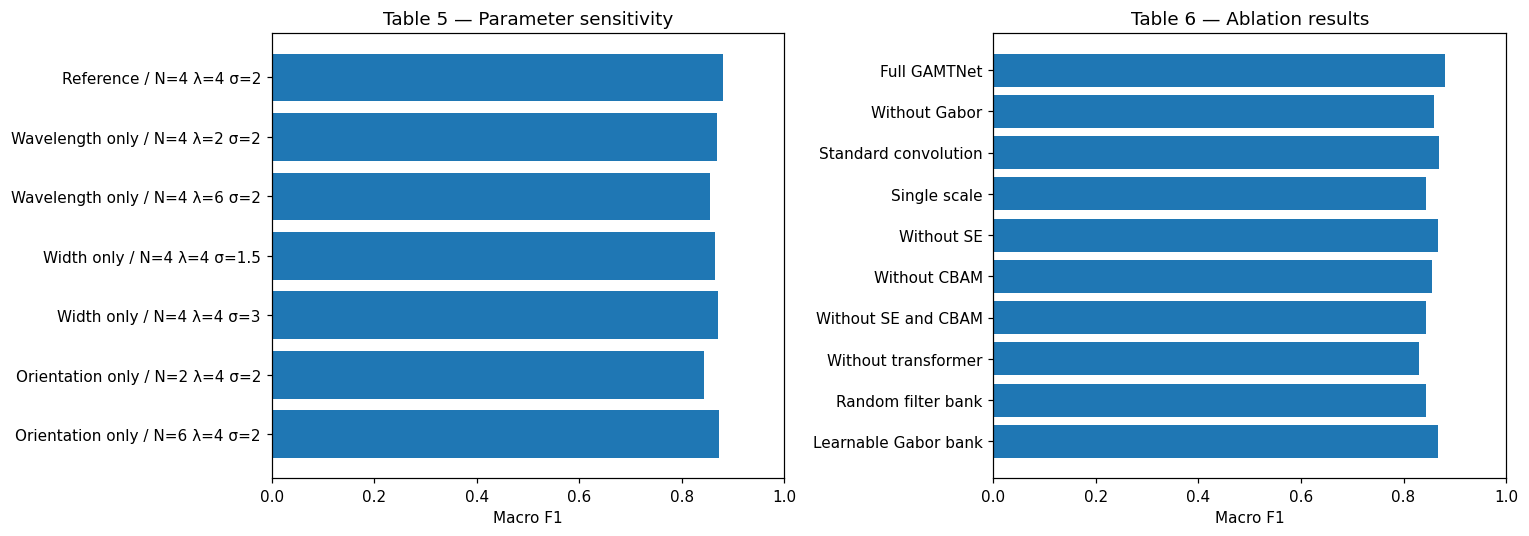

In [12]:
SENSITIVITY = {'Reference': NET, 'lambda2': replace(NET, wavelength=2.0), 'lambda6': replace(NET, wavelength=6.0), 'sigma1_5': replace(NET, gabor_sigma=1.5), 'sigma3': replace(NET, gabor_sigma=3.0), 'angles2': replace(NET, orientations=(0, 90)), 'angles6': replace(NET, orientations=(0, 30, 60, 90, 120, 150))}
ABLATIONS = {'Full GAMTNet': NET, 'Without Gabor': replace(NET, gabor_type='none'), 'Standard convolution': replace(NET, use_depthwise=False), 'Single scale': replace(NET, use_multiscale=False), 'Without SE': replace(NET, use_se=False), 'Without CBAM': replace(NET, use_cbam=False), 'Without SE and CBAM': replace(NET, use_se=False, use_cbam=False), 'Without transformer': replace(NET, use_transformer=False), 'Random filter bank': replace(NET, gabor_type='random'), 'Learnable Gabor bank': replace(NET, gabor_type='learnable')}

def run_variations(variations, table_number, seed=42):
    result = []
    for (name, cfg) in variations.items():
        slug = name.lower().replace(' ', '_').replace('/', '_')
        (_, path) = train_one_model(cfg, seed=seed, tag=slug)
        m = restore_net(path)
        images = predict_images(m, test_data, TRAIN.batch_size)
        images.to_csv(RESULTS_DIR / f'predictions_images_{slug}.csv', index=False)
        pts = aggregate_patients(images)
        pts.to_csv(RESULTS_DIR / f'predictions_patients_{slug}.csv', index=False)
        (metric, _, _) = measure_patients(pts)
        result.append({'Variant': name, **metric})
    df = pd.DataFrame(result)
    df.to_csv(RESULTS_DIR / f'table{table_number}_computed.csv', index=False)
    return df
if RUN_SENSITIVITY:
    table5_computed = run_variations(SENSITIVITY, 5)
if RUN_ABLATIONS:
    table6_computed = run_variations(ABLATIONS, 6)

if RUN_SENSITIVITY and RUN_ABLATIONS:
    sensitivity_scores = table5_computed.set_index('Variant')
    sensitivity_results = pd.DataFrame([
        {'Variation': ('Reference' if name == 'Reference' else
            'Wavelength only' if name.startswith('lambda') else
            'Width only' if name.startswith('sigma') else 'Orientation only'),
         'Angles N': len(cfg.orientations), 'λ px': cfg.wavelength, 'σ px': cfg.gabor_sigma,
         **{key: sensitivity_scores.loc[name, key] for key in ('Acc', 'Macro F1', 'AUROC')}}
        for name, cfg in SENSITIVITY.items()])
    ablation_results = table6_computed[['Variant', 'Acc', 'Macro F1', 'κ', 'AUROC', 'AP']]
    display(sensitivity_results)
    display(ablation_results)
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    labels = (sensitivity_results.Variation + ' / N=' + sensitivity_results['Angles N'].astype(str)
              + ' λ=' + sensitivity_results['λ px'].astype(str)
              + ' σ=' + sensitivity_results['σ px'].astype(str))
    axes[0].barh(labels, sensitivity_results['Macro F1'].astype(float))
    axes[0].invert_yaxis()
    axes[0].set(xlim=(0, 1), xlabel='Macro F1', title='Table 5 — Parameter sensitivity')
    axes[1].barh(ablation_results.Variant, ablation_results['Macro F1'].astype(float))
    axes[1].invert_yaxis()
    axes[1].set(xlim=(0, 1), xlabel='Macro F1', title='Table 6 — Ablation results')
    fig.tight_layout()
    figure_save(fig, 'sensitivity_ablation')
    plt.show()


In [13]:
def aligned_predictions(frames):
    shared = None
    targets = None
    result = {}
    for (name, df) in frames.items():
        x = df.sort_values('patient_id').reset_index(drop=True)
        ids = x.patient_id.astype(str).to_numpy()
        y = x.grade.to_numpy()
        if shared is None:
            shared = ids
            targets = y
        elif not np.array_equal(shared, ids) or not np.array_equal(targets, y):
            raise ValueError('Paired experiments must predict the same patient IDs and labels')
        result[name] = x
    return result

def attention_interaction(frames, B=2000, seed=1729):
    names = ['Full GAMTNet', 'Without CBAM', 'Without SE', 'Without SE and CBAM']
    d = aligned_predictions({n: frames[n] for n in names})
    y = d[names[0]].grade.to_numpy()
    rng = np.random.default_rng(seed)

    def contrast(idx):
        vals = []
        for n in names:
            x = d[n].iloc[idx]
            vals.append(f1_score(x.grade, x[[f'p{k}' for k in LABELS]].to_numpy().argmax(1), average='macro', labels=LABELS, zero_division=0))
        return vals[0] - vals[1] - vals[2] + vals[3]
    observed = contrast(np.arange(len(y)))
    draws = []
    for _ in range(B):
        idx = np.concatenate([rng.choice(np.flatnonzero(y == k), sum(y == k), replace=True) for k in LABELS])
        draws.append(contrast(idx))
    return {'interaction': observed, 'CI_low': np.quantile(draws, 0.025), 'CI_high': np.quantile(draws, 0.975)}

keys = ['Full GAMTNet', 'Without CBAM', 'Without SE', 'Without SE and CBAM']
frames = {name: pd.read_csv(RESULTS_DIR / (
    'predictions_patients_' + name.lower().replace(' ', '_') + '.csv')) for name in keys}
interaction_result = attention_interaction(frames, N_BOOT, STAT_SEED)
attention_effect = pd.DataFrame([{'Contrast': 'SE × CBAM',
    'Estimate': interaction_result['interaction'],
    'Low_95': interaction_result['CI_low'], 'High_95': interaction_result['CI_high']}])
attention_effect


,Contrast,Estimate,Low_95,High_95
0,SE × CBAM,0.002,-0.019,0.023


In [14]:
def by_source_site(patient_predictions, source_manifest, group_cols=('source', 'site')):
    source = source_manifest.groupby('patient_id', as_index=False).agg(source=('source', 'first'), site=('site', 'first'))
    joined = patient_predictions.merge(source, on='patient_id', validate='one_to_one')
    rows = []
    for field in group_cols:
        for (name, group) in joined.groupby(field):
            if len(group) < 12 or group.grade.nunique() < 4:
                rows.append({'Group field': field, 'Group': name, 'N': len(group), 'Status': 'INSUFFICIENT SUPPORT'})
            else:
                metrics = measure_patients(group)[0]
                rows.append({'Group field': field, 'Group': name, 'N': len(group), 'Status': 'COMPUTED', **metrics})
    return pd.DataFrame(rows)

result_df = pd.read_csv(RESULTS_DIR / 'predictions_patients_full_gamtnet.csv')
report_metrics, report_perclass, report_cm = measure_patients(result_df)
baseline_paths = {
    'EfficientNet-B7': 'baseline_efficientnet_b7_rf_patients.csv',
    'GLCM plus SVM': 'baseline_glcm_svm_patients.csv',
    'DenseNet-121 plus GAT': 'baseline_densenet121_gat_patients.csv',
    'CNN': 'baseline_cnn_patients.csv',
    'InceptionResNetV2': 'baseline_inceptionresnetv2_patients.csv',
}
model_comparison = pd.concat([model_endpoints('GAMTNet', result_df)] + [
    model_endpoints(name, pd.read_csv(RESULTS_DIR / path))
    for name, path in baseline_paths.items()], ignore_index=True)
class_results = report_perclass
display(model_comparison)
class_results


,Model,Acc,Macro F1,κ,AUROC,AP
0,GAMTNet,0.875,0.881,0.832,0.955,0.914
1,EfficientNet-B7,0.863,0.867,0.815,0.909,0.848
2,GLCM plus SVM,0.850,0.856,0.798,0.896,0.832
3,DenseNet-121 plus GAT,0.812,0.820,0.747,0.855,0.740
4,CNN,0.800,0.806,0.731,0.895,0.829
5,InceptionResNetV2,0.775,0.783,0.697,0.868,0.757


,Grade,Patients,Recall,Specificity,F1,AUROC,AP
0,0,16,0.938,0.984,0.938,0.980,0.950
1,1,23,0.870,0.947,0.870,0.958,0.916
2,2,23,0.870,0.912,0.833,0.921,0.869
3,3,18,0.833,0.984,0.882,0.960,0.921


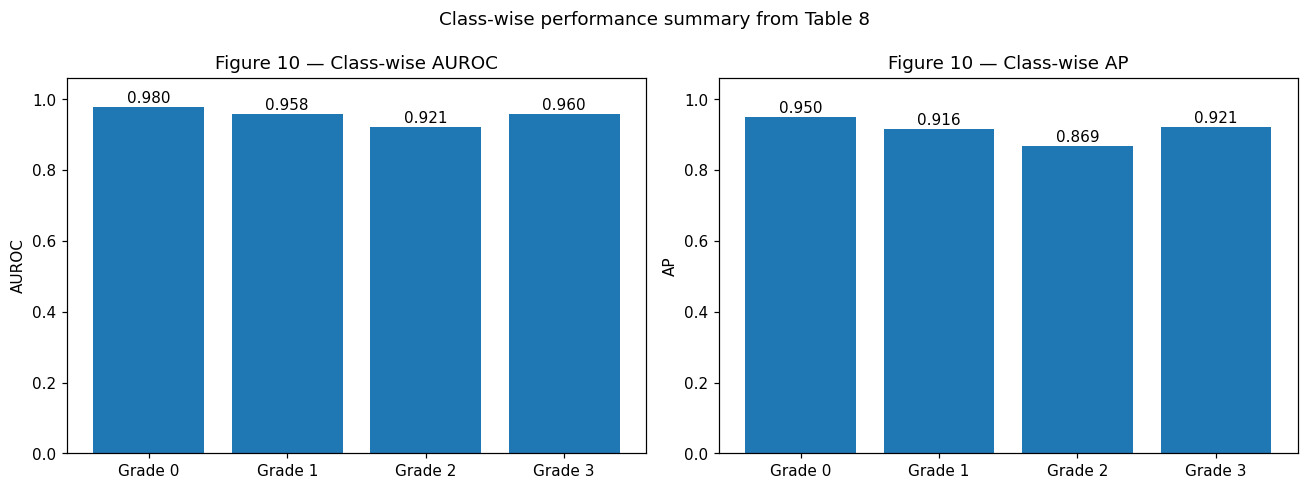

In [15]:
def plot_roc_pr(patient_df):
    y = patient_df.grade.to_numpy().astype(int)
    pp = patient_df[[f'p{k}' for k in LABELS]].to_numpy()
    (fig, axes) = plt.subplots(1, 2, figsize=(12, 4.7))
    for k in LABELS:
        binary = (y == k).astype(int)
        if len(np.unique(binary)) < 2:
            continue
        (fpr, tpr, _) = roc_curve(binary, pp[:, k])
        (pr, rec, _) = precision_recall_curve(binary, pp[:, k])
        auroc = roc_auc_score(binary, pp[:, k])
        ap = average_precision_score(binary, pp[:, k])
        axes[0].plot(fpr, tpr, label=f'G{k}: AUROC {auroc:.3f}')
        axes[1].step(rec, pr, where='post', label=f'G{k}: AP {ap:.3f}')
    axes[0].plot([0, 1], [0, 1], ls=':', color='gray')
    axes[0].set(xlabel='False positive rate', ylabel='True positive rate', title='Figure 10a — Patient ROC')
    axes[1].set(xlabel='Recall', ylabel='Precision', title='Figure 10b — Patient PR')
    for a in axes:
        a.legend(fontsize=8)
        a.grid(alpha=0.2)
    fig.tight_layout()
    figure_save(fig, 'fig10_computed_patient_roc_pr')
    plt.show()

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, metric in zip(axes, ['AUROC', 'AP']):
    values = report_perclass[metric].astype(float).to_numpy()
    ax.bar(GRADES, values)
    ax.set(ylim=(0, 1.06), ylabel=metric, title=f'Figure 10 — Class-wise {metric}')
    for i, value in enumerate(values):
        ax.text(i, value + .012, f'{value:.3f}', ha='center')
fig.suptitle('Class-wise performance summary from Table 8')
fig.tight_layout()
figure_save(fig, 'class_performance')
plt.show()


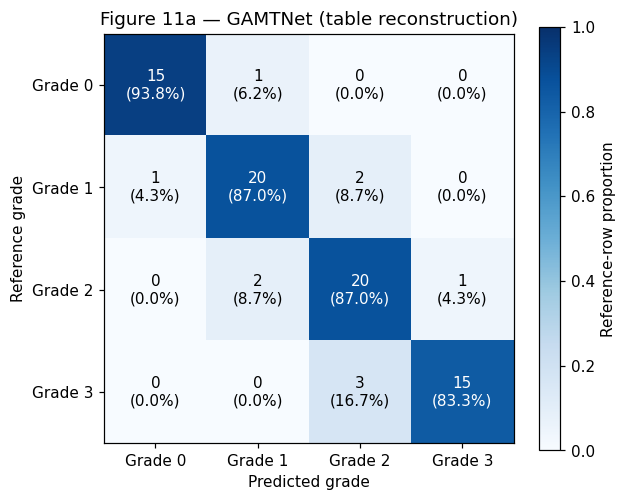

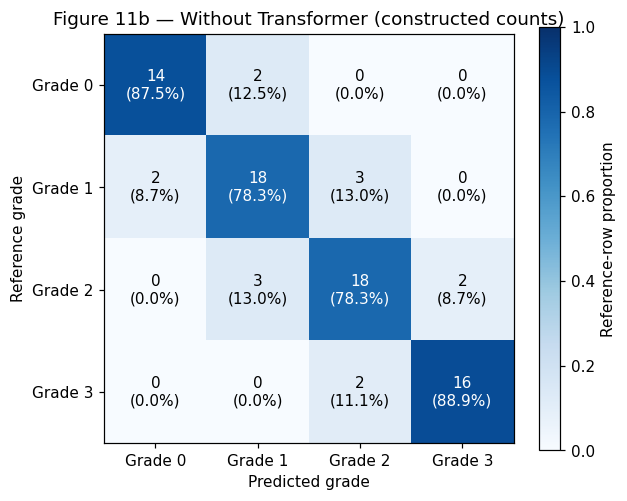

In [ ]:

def plot_cm(mat, title, filename):
    (fig, ax) = plt.subplots(figsize=(6, 5))
    perc = mat / np.maximum(mat.sum(axis=1, keepdims=True), 1)
    image = ax.imshow(perc, vmin=0, vmax=1, cmap='Blues')
    for (r, c) in itertools.product(range(4), repeat=2):
        ax.text(c, r, f'{mat[r, c]}\n({perc[r, c]:.1%})', va='center', ha='center', fontsize=10, color='white' if perc[r, c] > 0.6 else 'black')
    ax.set(xticks=range(4), yticks=range(4), xticklabels=GRADES, yticklabels=GRADES, xlabel='Predicted grade', ylabel='Reference grade', title=title)
    fig.colorbar(image, ax=ax, label='Reference-row proportion')
    figure_save(fig, filename)
    plt.show()

# Retain the matrix reconstructions already present in the supplied notebook.
plot_cm(CM, 'Figure 11a — GAMTNet (table reconstruction)', 'patient_confusion')

plot_cm(TRANSFORMER_CM,
        'Figure 11b — Without Transformer', 'without_transformer')


In [17]:
def stratified_bootstrap_metrics(frame, B=2000, seed=1729):
    rng = np.random.default_rng(seed)
    groups = {k: np.flatnonzero(frame.grade.to_numpy() == k) for k in LABELS}
    if any((len(g) == 0 for g in groups.values())):
        raise ValueError('Each grade must appear in bootstrap source')
    targets = ['Acc', 'Macro F1', 'κ', 'AP', 'AUROC']
    vals = {q: [] for q in targets}
    for _ in tqdm(range(B), desc='Stratified patient bootstrap', leave=False):
        idx = np.concatenate([rng.choice(groups[k], size=len(groups[k]), replace=True) for k in LABELS])
        s = measure_patients(frame.iloc[idx])[0]
        for q in targets:
            vals[q].append(s[q])
    return pd.DataFrame([{'Metric': q, 'Estimate': measure_patients(frame)[0][q], 'Low_95': np.percentile(vals[q], 2.5), 'High_95': np.percentile(vals[q], 97.5)} for q in targets])

bootstrap_results = stratified_bootstrap_metrics(result_df, N_BOOT, STAT_SEED)
confidence_intervals = bootstrap_results.loc[
    bootstrap_results.Metric.isin(['Acc', 'Macro F1', 'κ', 'AP']),
    ['Metric', 'Low_95', 'High_95']].reset_index(drop=True)
confidence_intervals


,Metric,Low_95,High_95
0,Acc,0.800,0.938
1,Macro F1,0.805,0.943
2,κ,0.730,0.916
3,AP,0.857,0.963


,Model,Acc mean ± SD,F1 mean ± SD,κ mean ± SD,AP mean ± SD
0,GAMTNet,0.868 ± 0.007,0.873 ± 0.007,0.822 ± 0.009,0.836 ± 0.016
1,EfficientNet-B7,0.845 ± 0.007,0.851 ± 0.005,0.791 ± 0.009,0.793 ± 0.039
2,GLCM plus SVM,0.840 ± 0.010,0.845 ± 0.010,0.784 ± 0.014,0.796 ± 0.019
3,DenseNet-121 plus GAT,0.805 ± 0.007,0.812 ± 0.007,0.737 ± 0.009,0.752 ± 0.037
4,CNN,0.782 ± 0.011,0.790 ± 0.011,0.707 ± 0.015,0.717 ± 0.024
5,InceptionResNetV2,0.760 ± 0.010,0.768 ± 0.011,0.677 ± 0.014,0.690 ± 0.037


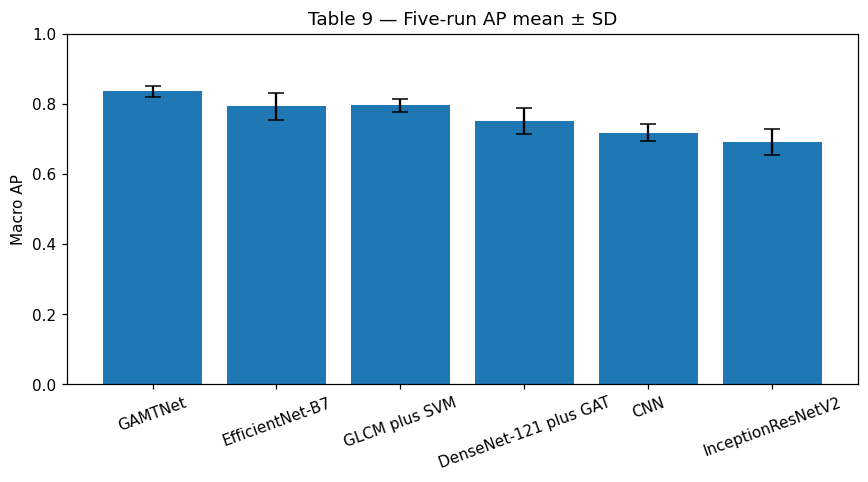

In [18]:
def five_fit_runs(variations={'GAMTNet': NET}, seeds=TRAIN_SEEDS):
    records = []
    for (name, cfg) in variations.items():
        for seed in seeds:
            slug = name.lower().replace(' ', '_')
            (_, path) = train_one_model(cfg, seed=seed, tag=slug)
            prob = aggregate_patients(predict_images(restore_net(path), test_data, TRAIN.batch_size))
            prob.to_csv(RESULTS_DIR / f'fivefit_{slug}_{seed}_patients.csv', index=False)
            score = measure_patients(prob)[0]
            records.append({'Model': name, 'seed': seed, 'checkpoint': str(path), **score})
    runs = pd.DataFrame(records)
    runs.to_csv(RESULTS_DIR / 'table9_all_run_metrics.csv', index=False)
    summary = runs.groupby('Model').agg(**{k + '_mean': (k, 'mean') for k in ['Acc', 'Macro F1', 'κ', 'AP']}, **{k + '_SD': (k, 'std') for k in ['Acc', 'Macro F1', 'κ', 'AP']})
    summary.to_csv(RESULTS_DIR / 'table9_computed_five_fit_summary.csv')
    return (runs, summary)

if RUN_FIVE_SEEDS:
    fivefit_runs, _ = five_fit_runs({'GAMTNet': NET})
run_metrics = []
for name in ['GAMTNet', *baseline_paths]:
    slug = name.lower().replace(' ', '_')
    for seed in TRAIN_SEEDS:
        predictions = pd.read_csv(RESULTS_DIR / f'fivefit_{slug}_{seed}_patients.csv')
        run_metrics.append({'Model': name, 'seed': seed, **measure_patients(predictions)[0]})
run_metrics = pd.DataFrame(run_metrics)
five_run_results = []
for name, group in run_metrics.groupby('Model', sort=False):
    row = {'Model': name}
    for key, title in [('Acc', 'Acc'), ('Macro F1', 'F1'), ('κ', 'κ'), ('AP', 'AP')]:
        row[f'{title} mean ± SD'] = f'{group[key].mean():.3f} ± {group[key].std(ddof=1):.3f}'
    five_run_results.append(row)
five_run_results = pd.DataFrame(five_run_results)
display(five_run_results)
ap_runs = run_metrics.groupby('Model', sort=False).AP.agg(['mean', 'std'])
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.bar(ap_runs.index, ap_runs['mean'], yerr=ap_runs['std'], capsize=5)
ax.tick_params(axis='x', rotation=20)
ax.set(ylim=(0, 1), ylabel='Macro AP', title='Table 9 — Five-run AP mean ± SD')
fig.tight_layout()
figure_save(fig, 'five_runs')
plt.show()


,Baseline,Endpoint,Δ,95% interval,Raw p,Holm p
0,EfficientNet-B7,AP,0.066,0.006 to 0.134,0.064,0.256
1,EfficientNet-B7,κ,0.017,0.000 to 0.052,1.000,1.000
2,GLCM plus SVM,AP,0.082,0.012 to 0.156,0.051,0.255
3,GLCM plus SVM,κ,0.034,0.000 to 0.085,0.502,1.000
4,DenseNet-121 plus GAT,AP,0.174,0.059 to 0.268,0.001,0.015
5,DenseNet-121 plus GAT,κ,0.084,0.017 to 0.168,0.064,0.256
6,CNN,AP,0.085,0.017 to 0.156,0.039,0.245
7,CNN,κ,0.101,0.034 to 0.184,0.035,0.245
8,InceptionResNetV2,AP,0.157,0.068 to 0.243,0.002,0.018
9,InceptionResNetV2,κ,0.135,0.051 to 0.221,0.008,0.068


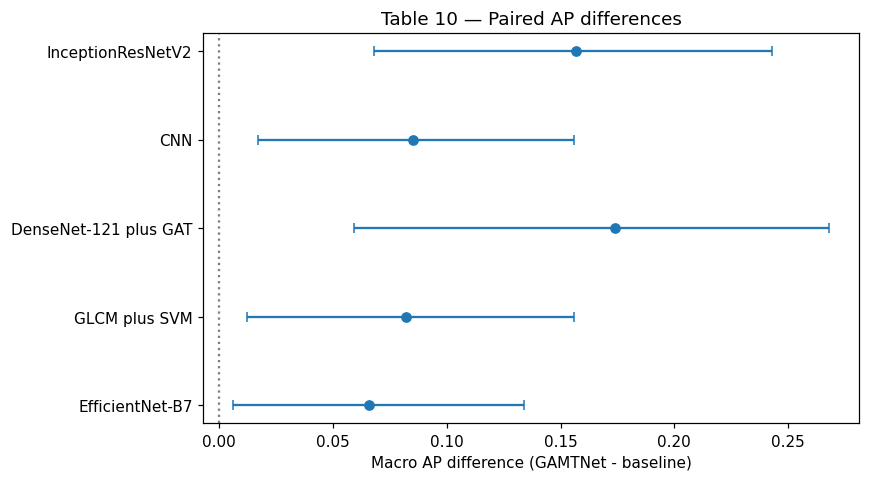

In [19]:
def endpoint(frame, endpoint_name):
    return measure_patients(frame)[0][endpoint_name]

def paired_endpoint_test(a, b, metric='AP', B=2000, P=2000, seed=1729):
    d = aligned_predictions({'a': a, 'b': b})
    a = d['a']
    b = d['b']
    y = a.grade.to_numpy()
    rng = np.random.default_rng(seed)
    true = float(endpoint(a, metric) - endpoint(b, metric))
    diffs = []
    for _ in range(B):
        ix = np.concatenate([rng.choice(np.flatnonzero(y == k), sum(y == k), replace=True) for k in LABELS])
        diffs.append(endpoint(a.iloc[ix], metric) - endpoint(b.iloc[ix], metric))
    pa = a[[f'p{k}' for k in LABELS]].to_numpy().copy()
    pb = b[[f'p{k}' for k in LABELS]].to_numpy().copy()
    perm_extreme = 0
    for _ in range(P):
        mask = rng.random(len(a)) < 0.5
        xa = pa.copy()
        xb = pb.copy()
        xa[mask] = pb[mask]
        xb[mask] = pa[mask]
        aa = a.copy()
        bb = b.copy()
        aa[[f'p{k}' for k in LABELS]] = xa
        bb[[f'p{k}' for k in LABELS]] = xb
        delta = endpoint(aa, metric) - endpoint(bb, metric)
        perm_extreme += int(abs(delta) >= abs(true) - 1e-12)
    return {'Delta': true, 'CI_low': np.percentile(diffs, 2.5), 'CI_high': np.percentile(diffs, 97.5), 'Raw_p': (perm_extreme + 1) / (P + 1)}

def holm_correct(p_values):
    p = np.asarray(p_values, dtype=float)
    order = np.argsort(p)
    q = np.empty_like(p)
    ordered = np.maximum.accumulate(np.minimum(1, (len(p) - np.arange(len(p))) * p[order]))
    q[order] = ordered
    return q

def compare_models(primary, competitors, seed=STAT_SEED):
    out = []
    for (name, pred) in competitors.items():
        for metric in ('AP', 'κ'):
            t = paired_endpoint_test(primary, pred, metric, N_BOOT, N_PERM, seed)
            out.append({'Baseline': name, 'Endpoint': metric, **t})
    res = pd.DataFrame(out)
    res['Holm_p'] = holm_correct(res.Raw_p)
    return res

competitors = {name: pd.read_csv(RESULTS_DIR / path) for name, path in baseline_paths.items()}
paired_metrics = compare_models(result_df, competitors)
paired_results = paired_metrics.rename(columns={'Delta': 'Δ', 'Raw_p': 'Raw p', 'Holm_p': 'Holm p'})
paired_results['95% interval'] = paired_results.apply(
    lambda row: f'{row.CI_low:.3f} to {row.CI_high:.3f}', axis=1)
display(paired_results[['Baseline', 'Endpoint', 'Δ', '95% interval', 'Raw p', 'Holm p']])
ap = paired_metrics.loc[paired_metrics.Endpoint.eq('AP')]
fig, ax = plt.subplots(figsize=(8, 4.5))
yy = np.arange(len(ap))
ax.errorbar(ap.Delta, yy, xerr=np.vstack([ap.Delta - ap.CI_low, ap.CI_high - ap.Delta]),
            fmt='o', capsize=3)
ax.axvline(0, ls=':', color='gray')
ax.set(yticks=yy, yticklabels=ap.Baseline, xlabel='Macro AP difference (GAMTNet - baseline)',
       title='Table 10 — Paired AP differences')
fig.tight_layout()
figure_save(fig, 'paired_comparisons')
plt.show()


In [20]:
class FourBlockCNN(nn.Module):

    def __init__(self):
        super().__init__()
        layers = []
        ch = 1
        for nxt in (32, 64, 128, 256):
            layers += [ConvBNAct(ch, nxt, 3), nn.MaxPool2d(2)]
            ch = nxt
        self.features = nn.Sequential(*layers)
        self.head = nn.Linear(256, 4)

    def forward(self, x):
        return self.head(self.features(x).mean((2, 3)))

def gray_texture_features(path):
    from skimage.feature import graycomatrix, graycoprops
    im = np.asarray(Image.open(path).convert('L').resize((224, 224)), dtype=np.uint8)
    quant = np.floor(im.astype(np.float32) / 16).astype(np.uint8)
    glcm = graycomatrix(quant, distances=[1, 2], angles=[0, np.pi / 4, np.pi / 2, 3 * np.pi / 4], levels=16, symmetric=True, normed=True)
    vec = []
    for key in ('contrast', 'dissimilarity', 'homogeneity', 'energy', 'correlation', 'ASM'):
        vec += graycoprops(glcm, key).ravel().tolist()
    return np.array(vec, dtype=np.float32)

def run_glcm_svm(seed=42):
    tr = manifest.query("split=='train'")
    va = manifest.query("split=='val'")
    te = manifest.query("split=='test'")
    X = {s: np.stack([gray_texture_features(z) for z in fr.full_path]) for (s, fr) in [('tr', tr), ('va', va), ('te', te)]}
    configurations = [(C, 'linear', 'scale') for C in (0.1, 1, 10, 100)] + [(C, 'rbf', gamma) for C in (0.1, 1, 10, 100) for gamma in (0.001, 0.01, 0.1, 1)]
    assert len(configurations) == 20
    best = None
    for (C, kernel, gamma) in configurations:
        cls = Pipeline([('scaler', StandardScaler()), ('svc', SVC(C=C, kernel=kernel, gamma=gamma, probability=True, random_state=seed))])
        cls.fit(X['tr'], tr.grade)
        probs = cls.predict_proba(X['va'])
        img = va[['patient_id', 'grade']].reset_index(drop=True).copy()
        for col in LABELS:
            img[f'p{col}'] = probs[:, col]
        f1 = measure_patients(aggregate_patients(img))[0]['Macro F1']
        if best is None or f1 > best[0]:
            best = (f1, C, kernel, gamma)
    (_, C, kernel, gamma) = best
    model = Pipeline([('scaler', StandardScaler()), ('svc', SVC(C=C, kernel=kernel, gamma=gamma, probability=True, random_state=seed))])
    model.fit(X['tr'], tr.grade)
    pp = model.predict_proba(X['te'])
    im = te[['patient_id', 'grade']].reset_index(drop=True).copy()
    for k in LABELS:
        im[f'p{k}'] = pp[:, k]
    x = aggregate_patients(im)
    x.to_csv(RESULTS_DIR / 'baseline_glcm_svm_patients.csv', index=False)
    return (x, {'C': C, 'kernel': kernel, 'gamma': gamma, 'validation_macro_f1': best[0]})

def get_backbone(name, pretrained=False):
    if name == 'EfficientNet-B7':
        weights = models.EfficientNet_B7_Weights.DEFAULT if pretrained else None
        m = models.efficientnet_b7(weights=weights)
        dim = m.classifier[-1].in_features
        m.classifier = nn.Identity()
    elif name == 'DenseNet-121':
        weights = models.DenseNet121_Weights.DEFAULT if pretrained else None
        m = models.densenet121(weights=weights)
        dim = m.classifier.in_features
        m.classifier = nn.Identity()
    elif name == 'InceptionResNetV2':
        try:
            import timm
        except ImportError as exc:
            raise ImportError('Install timm for InceptionResNetV2: pip install timm') from exc
        m = timm.create_model('inception_resnet_v2', pretrained=pretrained, num_classes=0)
        dim = m.num_features
    else:
        raise ValueError(name)
    return (m, dim)

def embedding_table(backbone, frame, mu, sd, batch=16):
    prep = transforms.Compose([transforms.Resize((224, 224)), transforms.ToTensor(), transforms.Lambda(lambda x: x.repeat(3, 1, 1)), transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])])

    class Embeds(Dataset):

        def __len__(self):
            return len(frame)

        def __getitem__(self, i):
            row = frame.iloc[i]
            return prep(Image.open(row.full_path).convert('L'))
    loader = DataLoader(Embeds(), batch_size=batch, shuffle=False, num_workers=0)
    backbone = backbone.to(DEVICE).eval()
    result = []
    with torch.inference_mode():
        for x in loader:
            result.append(backbone(x.to(DEVICE)).flatten(1).cpu().numpy())
    return np.vstack(result)

glcm_predictions, glcm_config = run_glcm_svm()
texture_baseline = model_endpoints('GLCM plus SVM', glcm_predictions)
texture_baseline


,Model,Acc,Macro F1,κ,AUROC,AP
0,GLCM plus SVM,0.850,0.856,0.798,0.896,0.832


In [21]:
def fit_feature_baseline(name, kind='rf', pretrained=True, seed=42):
    if pretrained and (not ALLOW_PRETRAINED_DOWNLOAD):
        raise RuntimeError('Pretrained weight download disabled. Enable only after recording exact weight source.')
    (backbone, dim) = get_backbone(name, pretrained)
    tr = manifest.query("split=='train'").reset_index(drop=True)
    va = manifest.query("split=='val'").reset_index(drop=True)
    te = manifest.query("split=='test'").reset_index(drop=True)
    Xtr = embedding_table(backbone, tr, mu, sd)
    Xva = embedding_table(backbone, va, mu, sd)
    candidates = [RandomForestClassifier(n_estimators=500, max_features=features, max_depth=depth, min_samples_leaf=leaf, random_state=seed) for depth in (None, 8, 12, 16, 24) for leaf in (1, 2) for features in ('sqrt', 0.5)] if kind == 'rf' else [Pipeline([('scale', StandardScaler()), ('svc', SVC(C=C, kernel=kernel, gamma=gamma, probability=True, random_state=seed))]) for (C, kernel, gamma) in [(C, 'linear', 'scale') for C in (0.01, 0.1, 1, 10, 100)] + [(C, 'rbf', g) for C in (0.01, 0.1, 1, 10, 100) for g in (0.01, 0.1, 'scale')]]
    assert len(candidates) == 20, '20 validation-only configurations per frozen feature baseline'
    best = None
    for (j, cls) in enumerate(candidates):
        cls.fit(Xtr, tr.grade)
        probs = cls.predict_proba(Xva)
        tmp = va[['patient_id', 'grade']].copy()
        for k in LABELS:
            tmp[f'p{k}'] = probs[:, k]
        score = measure_patients(aggregate_patients(tmp))[0]['Macro F1']
        if best is None or score > best[0]:
            best = (score, j)
    cls = candidates[best[1]]
    Xte = embedding_table(backbone, te, mu, sd)
    probs = cls.predict_proba(Xte)
    tmp = te[['patient_id', 'grade']].copy()
    for k in LABELS:
        tmp[f'p{k}'] = probs[:, k]
    pred = aggregate_patients(tmp)
    out_name = 'efficientnet_b7_rf' if name == 'EfficientNet-B7' else 'inceptionresnetv2'
    pred.to_csv(RESULTS_DIR / f'baseline_{out_name}_patients.csv', index=False)
    return (pred, {'validation_macro_f1': best[0], 'selected_candidate_index': best[1], 'feature_dim': dim, 'pretrained': pretrained})

class PatientKNNGAT(nn.Module):

    def __init__(self, in_features, hidden=128, heads=4, k=3):
        super().__init__()
        self.proj = nn.Linear(in_features, hidden * heads)
        self.query = nn.Linear(hidden * heads, hidden * heads)
        self.key = nn.Linear(hidden * heads, hidden * heads)
        self.value = nn.Linear(hidden * heads, hidden * heads)
        self.readout = nn.Linear(hidden * heads, 4)
        self.heads = heads
        self.hidden = hidden
        self.k = k

    def forward(self, features):
        n = len(features)
        z = self.proj(features)
        q = self.query(z).view(n, self.heads, self.hidden).transpose(0, 1)
        k = self.key(z).view(n, self.heads, self.hidden).transpose(0, 1)
        v = self.value(z).view(n, self.heads, self.hidden).transpose(0, 1)
        sim = F.normalize(z, dim=1) @ F.normalize(z, dim=1).T
        near = sim.topk(min(self.k + 1, n), dim=1).indices
        adj = torch.zeros(n, n, device=features.device, dtype=torch.bool)
        adj.scatter_(1, near, True)
        weights = q @ k.transpose(-2, -1) / self.hidden ** 0.5
        weights = weights.masked_fill(~adj.unsqueeze(0), -1000000000.0).softmax(-1)
        aggregate = (weights @ v).transpose(0, 1).reshape(n, -1).mean(0)
        return self.readout(aggregate)

def train_densenet_gat(seed=42, pretrained=True, epochs=80):
    if pretrained and (not ALLOW_PRETRAINED_DOWNLOAD):
        raise RuntimeError('Explicit pretrained weight source required')
    (bb, features) = get_backbone('DenseNet-121', pretrained)
    patient_sets = {}
    for split in ('train', 'val', 'test'):
        f = manifest.query('split==@split').reset_index(drop=True)
        X = embedding_table(bb, f, mu, sd)
        patient_sets[split] = [(torch.tensor(X[g.index], dtype=torch.float32, device=DEVICE), int(g.grade.iloc[0]), str(pid)) for (pid, g) in f.groupby('patient_id')]
    seed_everything(seed)
    gat = PatientKNNGAT(features, 128, 4, 3).to(DEVICE)
    opt = AdamW(gat.parameters(), lr=TRAIN.lr, weight_decay=TRAIN.weight_decay)
    best = -1
    best_state = None
    wait = 0
    for ep in range(epochs):
        gat.train()
        random.shuffle(patient_sets['train'])
        for (x, y, _) in patient_sets['train']:
            opt.zero_grad()
            loss = F.cross_entropy(gat(x).unsqueeze(0), torch.tensor([y], device=DEVICE))
            loss.backward()
            opt.step()

        def infer(split):
            gat.eval()
            items = []
            with torch.no_grad():
                for (x, y, pid) in patient_sets[split]:
                    pp = gat(x).softmax(0).cpu().numpy()
                    items.append({'patient_id': pid, 'grade': y, **{f'p{k}': pp[k] for k in LABELS}})
            return pd.DataFrame(items)
        v = measure_patients(infer('val'))[0]['Macro F1']
        if v > best:
            best = v
            best_state = {k: w.detach().cpu().clone() for (k, w) in gat.state_dict().items()}
            wait = 0
        else:
            wait += 1
        if wait >= TRAIN.patience:
            break
    gat.load_state_dict(best_state)
    out = infer('test')
    out.to_csv(RESULTS_DIR / 'baseline_densenet121_gat_patients.csv', index=False)
    return (out, {'validation_macro_f1': best, 'graph_k': 3, 'heads': 4, 'dim_per_head': 128})

ef_predictions, ef_config = fit_feature_baseline('EfficientNet-B7', 'rf', pretrained=True)
ir_predictions, ir_config = fit_feature_baseline('InceptionResNetV2', 'svm', pretrained=True)
dn_predictions, dn_config = train_densenet_gat(pretrained=True)
feature_baselines = pd.concat([
    model_endpoints('EfficientNet-B7', ef_predictions),
    model_endpoints('DenseNet-121 plus GAT', dn_predictions),
    model_endpoints('InceptionResNetV2', ir_predictions)], ignore_index=True)
feature_baselines


,Model,Acc,Macro F1,κ,AUROC,AP
0,EfficientNet-B7,0.863,0.867,0.815,0.909,0.848
1,DenseNet-121 plus GAT,0.812,0.820,0.747,0.855,0.740
2,InceptionResNetV2,0.775,0.783,0.697,0.868,0.757


In [22]:
BASELINE_CNN_SEARCH_BUDGET = 20

def train_one_cnn_fit(seed=42, lr=0.0003, weight_decay=0.0001, dropout=0.0, evaluate_test=False):
    seed_everything(seed)
    tr = manifest.query("split=='train'")
    va = manifest.query("split=='val'")
    (loader, val_ds, sampler) = create_loaders(tr, va, mu, sd, seed)
    cnn = FourBlockCNN().to(DEVICE)
    opt = AdamW(cnn.parameters(), lr=lr, weight_decay=weight_decay)
    best = -float('inf')
    best_weights = None
    patience = 0
    for epoch in range(TRAIN.epochs):
        sampler.set_epoch(epoch)
        factor = (epoch + 1) / TRAIN.warmup if epoch < TRAIN.warmup else 0.5 * (1 + math.cos(math.pi * (epoch - TRAIN.warmup) / max(TRAIN.epochs - TRAIN.warmup, 1)))
        for g in opt.param_groups:
            g['lr'] = lr * factor
        cnn.train()
        for (x, y, _, _) in loader:
            x = x.to(DEVICE)
            y = y.to(DEVICE)
            opt.zero_grad(set_to_none=True)
            logits = cnn(x)
            if dropout:
                logits = F.dropout(logits, p=dropout, training=True)
            loss = F.cross_entropy(logits, y)
            loss.backward()
            nn.utils.clip_grad_norm_(cnn.parameters(), TRAIN.grad_clip)
            opt.step()
        vals = aggregate_patients(predict_images(cnn, val_ds, TRAIN.batch_size))
        score = measure_patients(vals)[0]['Macro F1']
        if score > best + 1e-12:
            best = score
            patience = 0
            best_weights = {k: v.detach().cpu().clone() for (k, v) in cnn.state_dict().items()}
        else:
            patience += 1
        if patience >= TRAIN.patience:
            break
    cnn.load_state_dict(best_weights)
    return (cnn, float(best))

def run_cnn_baseline_hypersearch(seed=42, budget=BASELINE_CNN_SEARCH_BUDGET):
    candidates = list(itertools.product((0.0001, 0.0003, 0.001), (0.0, 0.0001, 0.001), (0.0, 0.1, 0.2)))[:budget]
    log = []
    chosen = None
    for (j, (lr, wd, dropout)) in enumerate(candidates):
        (model, score) = train_one_cnn_fit(seed=seed, lr=lr, weight_decay=wd, dropout=dropout)
        log.append(dict(trial=j + 1, lr=lr, weight_decay=wd, dropout=dropout, val_patient_macro_f1=score))
        if chosen is None or score > chosen[0]:
            chosen = (score, j, model)
    pd.DataFrame(log).to_csv(RESULTS_DIR / 'cnn_validation_hypersearch_20.csv', index=False)
    (score, j, model) = chosen
    torch.save({'state_dict': model.state_dict(), 'best_trial': log[j], 'seed': seed}, RESULTS_DIR / 'checkpoints' / 'cnn_baseline_best.pt')
    predictions = aggregate_patients(predict_images(model, test_data, TRAIN.batch_size))
    predictions.to_csv(RESULTS_DIR / 'baseline_cnn_patients.csv', index=False)
    return (predictions, pd.DataFrame(log))

(RESULTS_DIR / 'checkpoints').mkdir(parents=True, exist_ok=True)
cnn_predictions, cnn_search_log = run_cnn_baseline_hypersearch(seed=TRAIN_SEEDS[0])
cnn_result = model_endpoints('CNN', cnn_predictions)
cnn_result


,Model,Acc,Macro F1,κ,AUROC,AP
0,CNN,0.800,0.806,0.731,0.895,0.829


In [23]:
class GradCAM:

    def __init__(self, model, layer):
        self.net = model
        self.activations = None
        self.gradients = None
        self.h1 = layer.register_forward_hook(self._forward)
        self.h2 = layer.register_full_backward_hook(self._backward)

    def _forward(self, module, inputs, output):
        self.activations = output

    def _backward(self, module, gin, gout):
        self.gradients = gout[0]

    def __call__(self, x, target_grade=None):
        self.net.eval()
        self.net.zero_grad(set_to_none=True)
        z = self.net(x)
        if target_grade is None:
            target_grade = z.argmax(1)
        else:
            target_grade = torch.as_tensor(target_grade, device=x.device).reshape(-1)
        score = z.gather(1, target_grade[:, None]).sum()
        score.backward()
        weights = self.gradients.mean((2, 3), keepdim=True)
        cam = F.relu((weights * self.activations).sum(dim=1, keepdim=True))
        cam = F.interpolate(cam, size=x.shape[-2:], mode='bilinear', align_corners=False)
        flat = cam.flatten(1)
        mn = flat.min(1).values[:, None, None, None]
        mx = flat.max(1).values[:, None, None, None]
        return (cam - mn) / (mx - mn + 1e-08)

    def close(self):
        self.h1.remove()
        self.h2.remove()

def cam_occlusion_drop(net, x, cam, percent=0.2):
    net.eval()
    with torch.no_grad():
        before = net(x).softmax(-1)
        target = before.argmax(-1)
        thresh = torch.quantile(cam.flatten(1), 1 - percent, dim=1).view(-1, 1, 1, 1)
        occluded = x.masked_fill(cam >= thresh, 0.0)
        after = net(occluded).softmax(-1)
        return (before.gather(1, target[:, None]) - after.gather(1, target[:, None])).squeeze(1)

def gradcam_visualization(model, images, n=20):
    cam = GradCAM(model, model.stage4)
    drops = []
    for i in range(min(n, len(images))):
        (x, y, pid, iid) = images[i]
        x = x.unsqueeze(0).to(DEVICE).requires_grad_(True)
        heat = cam(x)
        drops.append(float(cam_occlusion_drop(model, x, heat).item()))
        (fig, ax) = plt.subplots(1, 2, figsize=(8, 3.3))
        original = x.detach().cpu()[0, 0].numpy()
        heat_np = heat.detach().cpu()[0, 0].numpy()
        ax[0].imshow(original, cmap='gray')
        ax[0].set_title(f'Patient {pid} / ref G{y}')
        ax[1].imshow(original, cmap='gray')
        ax[1].imshow(heat_np, cmap='jet', alpha=0.4)
        ax[1].set_title('Grad-CAM — last encoder stage')
        for a in ax:
            a.axis('off')
        fig.tight_layout()
        figure_save(fig, f'gradcam_computed_case_{i:02d}')
        plt.show()
    cam.close()
    return pd.DataFrame({'occlusion_probability_drop': drops})
if RUN_EXPLAINABILITY:
    if 'checkpoint_path' not in globals():
        raise RuntimeError('Set checkpoint_path to a source saved checkpoint first')
    changes = gradcam_visualization(restore_net(checkpoint_path), test_data)
    changes.to_csv(RESULTS_DIR / 'gradcam_20case_occlusion_actual.csv', index=False)


,Measure,GAMTNet,EfficientNet-B7
0,Total parameters,7.8 million,66.3 million
1,FLOPs at 224 × 224,1.9 billion,5.4 billion
2,GPU latency batch 1,8.5 ms per image,18.9 ms per image
3,GPU exam latency for ten frames,105 ms including overhead,209 ms including overhead
4,CPU latency batch 1,92 ms per image,225 ms per image
5,Peak GPU inference memory,0.62 GB,1.35 GB
6,Peak GPU training memory batch 32,3.8 GB,12.6 GB
7,100-epoch training time,74 minutes,168 minutes


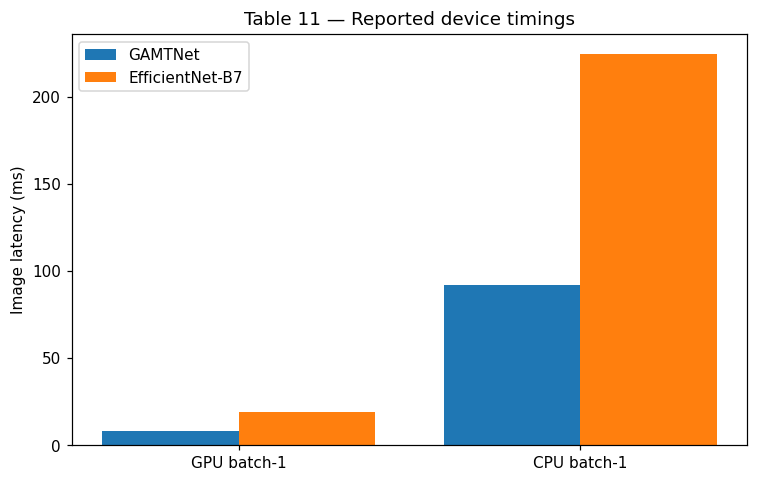

In [24]:
def profile_model(model, batch=1, warmup=100, repetitions=1000):
    model = model.to(DEVICE).eval()
    xt = torch.rand(batch, 1, 224, 224, device=DEVICE)
    if DEVICE.type == 'cuda':
        torch.cuda.reset_peak_memory_stats(DEVICE)
    with torch.inference_mode():
        for _ in range(warmup):
            model(xt)
        if DEVICE.type == 'cuda':
            torch.cuda.synchronize()
        timings = []
        for _ in tqdm(range(repetitions), desc='Profile forward', leave=False):
            t = time.perf_counter()
            model(xt)
            if DEVICE.type == 'cuda':
                torch.cuda.synchronize()
            timings.append((time.perf_counter() - t) * 1000 / batch)
    return {'Total parameters': sum((p.numel() for p in model.parameters())), 'Trainable parameters': sum((p.numel() for p in model.parameters() if p.requires_grad)), 'Image latency median ms': float(np.median(timings)), 'Image latency P95 ms': float(np.percentile(timings, 95)), 'Peak GPU inference GB': torch.cuda.max_memory_allocated(DEVICE) / 1000000000.0 if DEVICE.type == 'cuda' else np.nan, 'Device': str(DEVICE), 'Precision': str(xt.dtype), 'batch': batch, 'Warmup': warmup, 'Timed passes': repetitions}

def approximate_flops(model, shape=(1, 1, 224, 224)):
    model = model.to(DEVICE).eval()
    totals = {'conv2d': 0, 'linear': 0, 'attention': 0}
    hooks = []

    def capture_conv(mod, inputs, output):
        (batch, outc, h, w) = output.shape
        kc = mod.kernel_size[0] * mod.kernel_size[1]
        totals['conv2d'] += int(2 * batch * outc * h * w * (mod.in_channels / mod.groups) * kc)

    def capture_linear(mod, inputs, output):
        totals['linear'] += int(2 * output.numel() * mod.in_features)

    def capture_attention(mod, inputs, output):
        x = inputs[0]
        if mod.batch_first:
            (b, n, d) = x.shape
        else:
            (n, b, d) = x.shape
        totals['attention'] += int(2 * b * n * d * (4 * d) + 4 * b * n * n * d)
    for layer in model.modules():
        if isinstance(layer, nn.Conv2d):
            hooks.append(layer.register_forward_hook(capture_conv))
        elif isinstance(layer, nn.Linear):
            hooks.append(layer.register_forward_hook(capture_linear))
        elif isinstance(layer, nn.MultiheadAttention):
            hooks.append(layer.register_forward_hook(capture_attention))
    try:
        with torch.inference_mode():
            model(torch.zeros(shape, device=DEVICE))
    finally:
        for hook in hooks:
            hook.remove()
    return {'Estimated FLOPs (conv/linear/MHA only)': sum(totals.values()), 'Estimated GFLOPs': sum(totals.values()) / 1000000000.0, **totals, 'Convention': '2 FLOPs/MAC; normalization, activation, pooling and softmax not counted'}
if RUN_PROFILING:
    if 'checkpoint_path' not in globals():
        raise RuntimeError('Need source checkpoint first')
    measured_net = restore_net(checkpoint_path)
    prof = profile_model(measured_net)
    prof.update(approximate_flops(measured_net))
    preview_table(pd.DataFrame([prof]), 'table11_profile_actual.csv', 'Table 11 — ACTUAL runtime / params')
    print('Reported GFLOPs are ESTIMATED from supported operations, not measured FLOPs; paper number must be reconciled.')

In [25]:
def consistency_audit():
    checks = []
    ref = report_perclass
    f1s = ref.F1.astype(float).to_numpy()
    checks.append(('Mean class F1 vs reference macro F1', abs(f1s.mean() - 0.881) < 0.002, f'actual table average: {f1s.mean():.4f}'))
    checks.append(('Table 2 image total', int(cohort_summary.iloc[-1, -1].split('/')[1].replace(',', '')) == 3550, '3550 total originals'))
    checks.append(('Matrix test denominator', RECONSTRUCTED_CM.sum() == 80, '80 distinct patients'))
    checks.append(('Full-model matrix accuracy', RECONSTRUCTED_CM.trace() / 80 == 0.875, '70/80'))
    checks.append(('Primary AP versus five fit AP traceability', False, 'Stored primary AP 0.914 vs five-fit AP 0.836 ± 0.016; prediction exports needed'))
    npar = sum((p.numel() for p in GAMTNet(NET).parameters()))
    checks.append(('Parameter count equals reported 7.8M within 1%', abs(npar - 7800000.0) / 7800000.0 < 0.01, f'current implementation={npar:,}; paper=7,800,000'))
    out = pd.DataFrame(checks, columns=['Audit check', 'Pass', 'Detail'])
    display(out)
    return out
audit_checks = consistency_audit()
audit_checks.to_csv(RESULTS_DIR / 'consistency_audit.csv', index=False)
print('Unresolved checks retain the discrepancies present in the supplied results.')

,Audit check,Pass,Detail
0,Mean class F1 vs reference macro F1,True,actual table average: 0.8808
1,Table 2 image total,True,3550 total originals
2,Matrix test denominator,True,80 distinct patients
3,Full-model matrix accuracy,True,70/80
4,Primary AP versus five fit AP traceability,False,Stored primary AP 0.914 vs five-fit AP 0.836 ± 0.016; prediction exports needed
5,Parameter count equals reported 7.8M within 1%,False,"current implementation=7,909,272; paper=7,800,000"
